# # 💬 UnifyComm — Notebook 2: Sentiment Analysis + Unified Demo
#
# **Objective:** Load a pretrained sentiment model (CardiffNLP), evaluate it on
# banking-specific customer messages, then build a unified demo that runs BOTH
# intent classification and sentiment analysis on any input message.
#
# **No fine-tuning** — we use the pretrained model as-is since CardiffNLP's
# twitter-roberta-base-sentiment-latest is already strong on short, informal text.
#
# **Hardware:** Google Colab free tier (GPU optional, CPU is fine for inference)
# **Estimated Total Runtime:** ~10 minutes
#

In [ ]:
!pip install transformers==4.36.2 datasets==2.16.1 accelerate==0.25.0 scikit-learn==1.3.2 matplotlib==3.8.2 seaborn==0.13.1 pandas==2.1.4 numpy==1.24.3 torch==2.1.2 scipy --quiet

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 126.8/126.8 kB 4.9 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.9/10.9 MB 114.1 MB/s eta 0:00:00
  Installing build dependencies ... done
  error: subprocess-exited-with-error
  
  × Getting requirements to build wheel did not run successfully.
  │ exit code: 1
  ╰─> See above for output.
  
  note: This error originates from a subprocess, and is likely not a problem with pip.
  Getting requirements to build wheel ... error
error: subprocess-exited-with-error

× Getting requirements to build wheel did not run successfully.
│ exit code: 1
╰─> See above for output.

note: This error originates from a subprocess, and is likely not a problem with pip.


In [ ]:
# %%
import os
import json
import time
import random
import warnings
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
from transformers import (
    AutoTokenizer,
    AutoModel,
    AutoModelForSequenceClassification,
    AutoConfig,
    pipeline,
    set_seed,
)
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
)

warnings.filterwarnings("ignore")
set_seed(42)
random.seed(42)
np.random.seed(42)
torch.manual_seed(42)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device: {device}")
print("✅ All imports successful!")

Device: cuda
✅ All imports successful!


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

DRIVE_BASE = "/content/drive/MyDrive/UnifyComm"
INTENT_MODEL_DIR = f"{DRIVE_BASE}/models/intent/final_model"
SENTIMENT_DIR = f"{DRIVE_BASE}/models/sentiment"
os.makedirs(SENTIMENT_DIR, exist_ok=True)

print(f"✅ Drive mounted")
print(f"  Intent model:   {INTENT_MODEL_DIR}")
print(f"  Sentiment save: {SENTIMENT_DIR}")

Mounted at /content/drive
✅ Drive mounted
  Intent model:   /content/drive/MyDrive/UnifyComm/models/intent/final_model
  Sentiment save: /content/drive/MyDrive/UnifyComm/models/sentiment


# %% [markdown]
# ## 2. Load CardiffNLP Sentiment Model
# `cardiffnlp/twitter-roberta-base-sentiment-latest` is a RoBERTa model
# fine-tuned on ~124M tweets for 3-class sentiment (positive/negative/neutral).
# It's ideal for short, informal text like customer messages.
# **Estimated time: ~2 minutes (download)**

In [ ]:
SENTIMENT_MODEL_NAME = "cardiffnlp/twitter-roberta-base-sentiment-latest"

print(f"📥 Loading sentiment model: {SENTIMENT_MODEL_NAME}")
print("  This may take 1-2 minutes on first download...")

sentiment_pipeline = pipeline(
    "sentiment-analysis",
    model=SENTIMENT_MODEL_NAME,
    tokenizer=SENTIMENT_MODEL_NAME,
    device=0 if torch.cuda.is_available() else -1,
    top_k=None,  # Return scores for all classes
)

# Quick test
test_result = sentiment_pipeline("I love this bank service!")
print(f"\n✅ Sentiment model loaded!")
print(f"  Test: 'I love this bank service!'")
print(f"  Result: {test_result}")

# Save model to Drive for future use (avoids re-downloading)
print(f"\n💾 Caching model to Drive...")
sentiment_pipeline.model.save_pretrained(f"{SENTIMENT_DIR}/model_cache")
sentiment_pipeline.tokenizer.save_pretrained(f"{SENTIMENT_DIR}/model_cache")
print("  ✅ Model cached to Drive")

📥 Loading sentiment model: cardiffnlp/twitter-roberta-base-sentiment-latest
  This may take 1-2 minutes on first download...


config.json:   0%|          | 0.00/929 [00:00<?, ?B/s]

pytorch_model.bin:   0%|          | 0.00/501M [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/501M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

...

merges.txt: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/239 [00:00<?, ?B/s]


✅ Sentiment model loaded!
  Test: 'I love this bank service!'
  Result: [[{'label': 'positive', 'score': 0.9861198663711548}, {'label': 'neutral', 'score': 0.009848233312368393}, {'label': 'negative', 'score': 0.0040318951942026615}]]

💾 Caching model to Drive...


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

  ✅ Model cached to Drive


# %% [markdown]
# ## 3. Create Banking Evaluation Dataset
# We manually create 50 realistic banking customer messages with ground truth
# labels. These cover real-world scenarios: transaction failures, complaints,
# thank you messages, balance enquiries, etc.
# Messages are kept short and informal to mimic real WhatsApp/SMS style.

In [ ]:
# Labeled test set: 50 banking customer messages
# Distribution: 20 negative, 20 positive, 10 neutral
evaluation_data = [
    # === NEGATIVE (20) ===
    # Transaction failures and money issues
    {"text": "my transaction failed but money got deducted from my account", "label": "negative"},
    {"text": "i transferred money 3 days ago still not received by beneficiary", "label": "negative"},
    {"text": "atm ate my card and charged me 500 rs for nothing", "label": "negative"},
    {"text": "emi got deducted twice this month please help", "label": "negative"},
    {"text": "my salary credit is delayed again this is the 3rd time", "label": "negative"},
    # Complaints about service
    {"text": "horrible customer service nobody picks up the phone", "label": "negative"},
    {"text": "your app keeps crashing whenever i try to make a payment", "label": "negative"},
    {"text": "i have been waiting for my new card for 3 weeks this is unacceptable", "label": "negative"},
    {"text": "why is my account blocked without any notice", "label": "negative"},
    {"text": "net banking password not working even after reset", "label": "negative"},
    # Account and card issues
    {"text": "someone made unauthorized transactions on my credit card", "label": "negative"},
    {"text": "my fixed deposit matured but amount not credited", "label": "negative"},
    {"text": "loan emi calculation seems wrong i am being overcharged", "label": "negative"},
    {"text": "card not working at any atm tried 5 different machines", "label": "negative"},
    {"text": "my cheque bounced even though i have sufficient balance", "label": "negative"},
    # Frustration and urgency
    {"text": "this is the worst bank i have ever used switching immediately", "label": "negative"},
    {"text": "still havent received my refund its been 2 months now", "label": "negative"},
    {"text": "debit card got stolen and someone withdrew all my money", "label": "negative"},
    {"text": "insurance claim rejected without proper reason very disappointed", "label": "negative"},
    {"text": "hidden charges in my savings account this is fraud", "label": "negative"},

    # === POSITIVE (20) ===
    # Successful transactions
    {"text": "loan approved thank you so much for quick processing", "label": "positive"},
    {"text": "finally received my new credit card loving the rewards", "label": "positive"},
    {"text": "money transferred successfully within seconds great service", "label": "positive"},
    {"text": "my fixed deposit interest rate is really good compared to others", "label": "positive"},
    {"text": "salary got credited on time as always thank you", "label": "positive"},
    # Praise and satisfaction
    {"text": "your customer support team is amazing resolved my issue in 5 min", "label": "positive"},
    {"text": "the mobile app is so easy to use love the new update", "label": "positive"},
    {"text": "best banking experience ever will definitely recommend to friends", "label": "positive"},
    {"text": "thank you for waiving the annual card fee really appreciate it", "label": "positive"},
    {"text": "instant loan disbursement was a lifesaver in my emergency", "label": "positive"},
    # Approvals and good news
    {"text": "home loan approved at great interest rate very happy", "label": "positive"},
    {"text": "cashback received for online shopping thanks for the offer", "label": "positive"},
    {"text": "new savings account opened very smoothly in just 10 minutes", "label": "positive"},
    {"text": "refund processed and received successfully thank you team", "label": "positive"},
    {"text": "insurance claim settled quickly really impressed with the service", "label": "positive"},
    # General happiness
    {"text": "your investment advice helped me earn great returns", "label": "positive"},
    {"text": "upi payment went through perfectly every single time", "label": "positive"},
    {"text": "excellent support on chat issue resolved without calling", "label": "positive"},
    {"text": "upgraded to platinum card the lounge access benefit is wonderful", "label": "positive"},
    {"text": "really happy with the zero balance account no hidden fees", "label": "positive"},

    # === NEUTRAL (10) ===
    # Balance and information enquiries
    {"text": "what is my current account balance", "label": "neutral"},
    {"text": "what are the charges for neft transfer", "label": "neutral"},
    {"text": "i need to update my kyc documents", "label": "neutral"},
    {"text": "how do i add a new beneficiary for fund transfer", "label": "neutral"},
    {"text": "when will my cheque get cleared", "label": "neutral"},
    {"text": "what is the minimum balance requirement for savings account", "label": "neutral"},
    {"text": "can you tell me the nearest branch address", "label": "neutral"},
    {"text": "what documents are needed for home loan application", "label": "neutral"},
    {"text": "how to change my registered mobile number", "label": "neutral"},
    {"text": "what is the current fd interest rate for 1 year", "label": "neutral"},
]

eval_df = pd.DataFrame(evaluation_data)
print(f"✅ Evaluation dataset created: {len(eval_df)} messages")
print(f"\n📊 Label distribution:")
print(eval_df['label'].value_counts().to_string())

✅ Evaluation dataset created: 50 messages

📊 Label distribution:
label
negative    20
positive    20
neutral     10


# %% [markdown]
# ## 4. Evaluate Sentiment Model + Plots
# Run the sentiment model on all 50 messages, compare with ground truth,
# and generate evaluation metrics and visualizations.
# **Estimated time: ~2 minutes**

In [ ]:
# Map CardiffNLP labels to our standard labels
# CardiffNLP uses: "positive", "negative", "neutral" (already matching)
CARDIFF_LABEL_MAP = {
    'positive': 'positive',
    'negative': 'negative',
    'neutral': 'neutral',
}

print("🔍 Running sentiment model on evaluation dataset...")
predictions = []
confidences = []
all_scores = []

for i, row in eval_df.iterrows():
    result = sentiment_pipeline(row['text'])[0]  # top_k=None returns list of dicts

    # Parse scores for each class
    scores_dict = {}
    for entry in result:
        mapped_label = CARDIFF_LABEL_MAP.get(entry['label'].lower(), entry['label'].lower())
        scores_dict[mapped_label] = entry['score']

    # Get predicted label (highest score)
    pred_label = max(scores_dict, key=scores_dict.get)
    pred_confidence = scores_dict[pred_label]

    predictions.append(pred_label)
    confidences.append(pred_confidence)
    all_scores.append(scores_dict)

    if (i + 1) % 10 == 0:
        print(f"  Processed {i+1}/{len(eval_df)} messages...")

eval_df['predicted'] = predictions
eval_df['confidence'] = confidences
eval_df['scores'] = all_scores

print(f"\n✅ All {len(eval_df)} messages evaluated!")


🔍 Running sentiment model on evaluation dataset...


You seem to be using the pipelines sequentially on GPU. In order to maximize efficiency please use a dataset


  Processed 10/50 messages...
  Processed 20/50 messages...
  Processed 30/50 messages...
  Processed 40/50 messages...
  Processed 50/50 messages...

✅ All 50 messages evaluated!


In [ ]:
# --- Metrics ---
true_labels = eval_df['label'].tolist()
pred_labels = eval_df['predicted'].tolist()
all_classes = ['negative', 'neutral', 'positive']

accuracy = accuracy_score(true_labels, pred_labels)
macro_f1 = f1_score(true_labels, pred_labels, average='macro')
weighted_f1 = f1_score(true_labels, pred_labels, average='weighted')

print("\n" + "=" * 60)
print("📊 SENTIMENT MODEL EVALUATION RESULTS")
print("=" * 60)
print(f"\n  Accuracy:     {accuracy:.4f} ({accuracy*100:.1f}%)")
print(f"  Macro F1:     {macro_f1:.4f}")
print(f"  Weighted F1:  {weighted_f1:.4f}")
print(f"\n  Classification Report:")
print(classification_report(true_labels, pred_labels, target_names=all_classes, digits=4))


📊 SENTIMENT MODEL EVALUATION RESULTS

  Accuracy:     0.9600 (96.0%)
  Macro F1:     0.9522
  Weighted F1:  0.9608

  Classification Report:
              precision    recall  f1-score   support

    negative     1.0000    0.9000    0.9474        20
     neutral     0.8333    1.0000    0.9091        10
    positive     1.0000    1.0000    1.0000        20

    accuracy                         0.9600        50
   macro avg     0.9444    0.9667    0.9522        50
weighted avg     0.9667    0.9600    0.9608        50



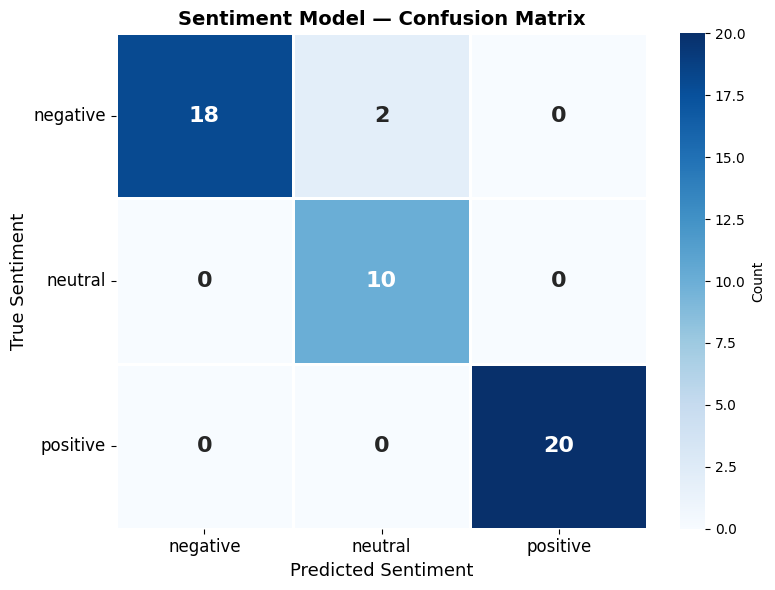

💾 confusion_matrix_sentiment.png saved!


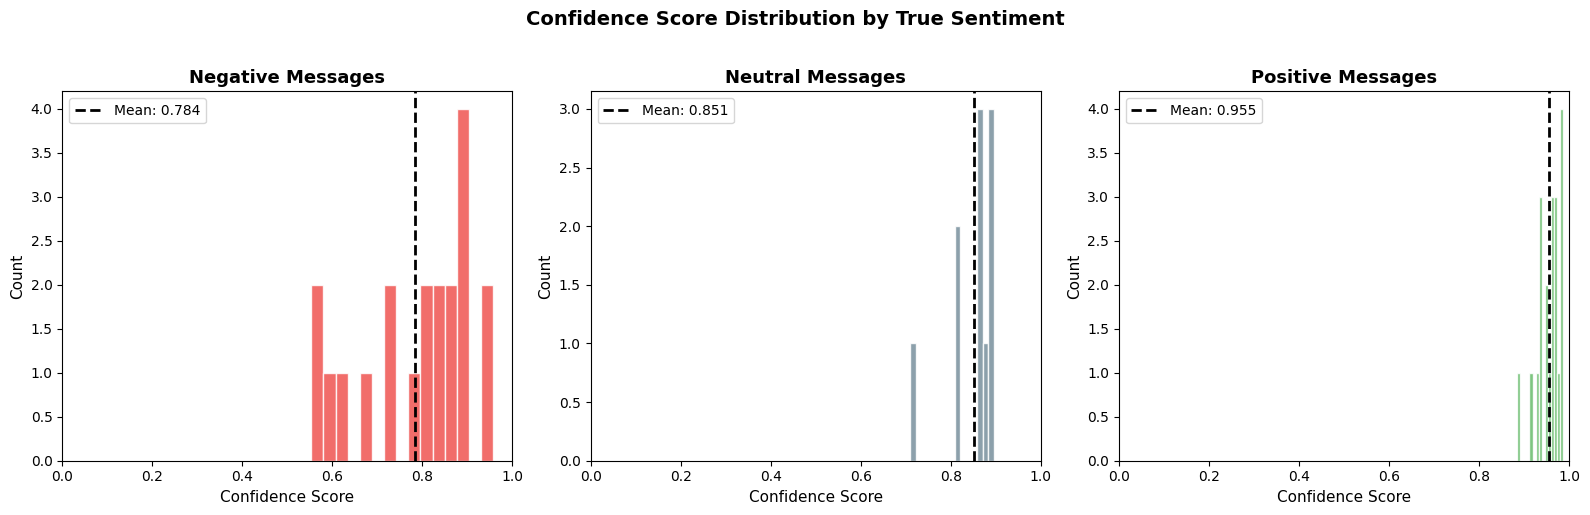

💾 confidence_distribution.png saved!


In [ ]:
# --- PLOT 1: Confusion Matrix ---
cm = confusion_matrix(true_labels, pred_labels, labels=all_classes)

fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=all_classes, yticklabels=all_classes,
            ax=ax, linewidths=1, linecolor='white',
            annot_kws={'size': 16, 'fontweight': 'bold'},
            cbar_kws={'label': 'Count'})
ax.set_xlabel("Predicted Sentiment", fontsize=13)
ax.set_ylabel("True Sentiment", fontsize=13)
ax.set_title("Sentiment Model — Confusion Matrix", fontsize=14, fontweight='bold')
plt.xticks(fontsize=12)
plt.yticks(fontsize=12, rotation=0)
plt.tight_layout()
plt.savefig(f"{SENTIMENT_DIR}/confusion_matrix_sentiment.png", dpi=150, bbox_inches='tight')
plt.show()
print("💾 confusion_matrix_sentiment.png saved!")

# %%
# --- PLOT 2: Confidence Score Distribution ---
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for idx, sentiment in enumerate(all_classes):
    mask = eval_df['label'] == sentiment
    subset_conf = eval_df.loc[mask, 'confidence']

    color_map = {'negative': '#EF5350', 'neutral': '#78909C', 'positive': '#66BB6A'}
    axes[idx].hist(subset_conf, bins=15, color=color_map[sentiment],
                   edgecolor='white', alpha=0.85)
    axes[idx].axvline(x=subset_conf.mean(), color='black', linestyle='--',
                      linewidth=2, label=f'Mean: {subset_conf.mean():.3f}')
    axes[idx].set_xlabel("Confidence Score", fontsize=11)
    axes[idx].set_ylabel("Count", fontsize=11)
    axes[idx].set_title(f"{sentiment.capitalize()} Messages", fontsize=13, fontweight='bold')
    axes[idx].legend(fontsize=10)
    axes[idx].set_xlim(0, 1)

plt.suptitle("Confidence Score Distribution by True Sentiment", fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig(f"{SENTIMENT_DIR}/confidence_distribution.png", dpi=150, bbox_inches='tight')
plt.show()
print("💾 confidence_distribution.png saved!")

In [ ]:
# %%
def analyze_sentiment(text):
    """Analyze sentiment of a single message and print results."""
    all_scores = sentiment_pipeline(text, top_k=3)
    # Pipeline may return nested list — flatten if needed
    if isinstance(all_scores[0], list):
        all_scores = all_scores[0]

    top = all_scores[0]  # Highest confidence prediction
    emoji_map = {"positive": "😊", "negative": "😠", "neutral": "😐"}

    print(f"\n📩 Input: \"{text}\"")
    print(f"{'─' * 50}")
    print(f"  Sentiment: {emoji_map.get(top['label'], '')} {top['label'].upper()}")
    print(f"  Confidence: {top['score']:.4f}")
    print(f"\n  All scores:")
    for s in all_scores:
        bar = "█" * int(s['score'] * 30)
        print(f"    {s['label']:10s} {s['score']:.4f} {bar}")

# --- Try it! ---
test_messages = [
    "I love the new mobile banking features!",
    "I was charged twice and nobody is helping me",
    "I need to update my phone number on my account",
    "This is the worst bank I have ever used",
    "Can you tell me my account balance?",
]

for msg in test_messages:
    analyze_sentiment(msg)



📩 Input: "I love the new mobile banking features!"
──────────────────────────────────────────────────
  Sentiment: 😊 POSITIVE
  Confidence: 0.9893

  All scores:
    positive   0.9893 █████████████████████████████
    neutral    0.0085 
    negative   0.0023 

📩 Input: "I was charged twice and nobody is helping me"
──────────────────────────────────────────────────
  Sentiment: 😠 NEGATIVE
  Confidence: 0.9281

  All scores:
    negative   0.9281 ███████████████████████████
    neutral    0.0667 █
    positive   0.0053 

📩 Input: "I need to update my phone number on my account"
──────────────────────────────────────────────────
  Sentiment: 😐 NEUTRAL
  Confidence: 0.8342

  All scores:
    neutral    0.8342 █████████████████████████
    negative   0.0842 ██
    positive   0.0816 ██

📩 Input: "This is the worst bank I have ever used"
──────────────────────────────────────────────────
  Sentiment: 😠 NEGATIVE
  Confidence: 0.9488

  All scores:
    negative   0.9488 ██████████████████████